### REDUCCION DE IMAGENES

In [1]:
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy import units as u
from astropy.visualization import ZScaleInterval
from astropy.coordinates import SkyCoord
from astropy.stats import sigma_clipped_stats
from astropy.wcs import WCS
from scipy import ndimage
import astroalign as aa

#seeing medido en las estrellas estandar: media de B = 3.14", media de V = 3.20"
PIXSCALE = 0.317                #"/px
SEEING = (3.14 + 3.20)/2        #"
FWHM_PX = SEEING/PIXSCALE       #FWHM en px (~10), se usa para alinear y detectar

*IMPORTANTE* los flats son de 0.5 s y los darks de 120 s, por tanto restarlos directamente esta mal: a los flats solo se les resta el nivel cero del detector (mediana del master dark)

In [2]:
#abrimos las imagenes de NGC7793 en el filtro B
b1=fits.open('NGC_7793_B_120.000secs_00000727.fit') 
b2=fits.open('NGC_7793_B_120.000secs_00000728.fit') #fit 728 ccorrido
b3=fits.open('NGC_7793_B_120.000secs_00000729.fit') 
b4=fits.open('NGC_7793_B_120.000secs_00000730.fit') #el fit 730 es malo
b5=fits.open('NGC_7793_B_120.000secs_00000731.fit')


In [3]:
#abrimos las imagenes de NGC7793 en el filtro V
v1=fits.open('NGC_7793_V_120.000secs_00000723.fit') #cutie
v2=fits.open('NGC_7793_V_120.000secs_00000724.fit') #this bitch is ugly
v3=fits.open('NGC_7793_V_120.000secs_00000725.fit') # LA UNICA NO CORRIDA
v4=fits.open('NGC_7793_V_120.000secs_00000726.fit')#FEA ATAOOOOOO


In [4]:
#extraemos las imagenes filtro b
datab1=b1[0].data.astype(np.float32)
datab2=b2[0].data.astype(np.float32)
datab3=b3[0].data.astype(np.float32)
datab4=b4[0].data.astype(np.float32)
datab5=b5[0].data.astype(np.float32)

#extraemos las imagenes filtro v
datav1=v1[0].data.astype(np.float32)
datav2=v2[0].data.astype(np.float32)
datav3=v3[0].data.astype(np.float32)
datav4=v4[0].data.astype(np.float32)


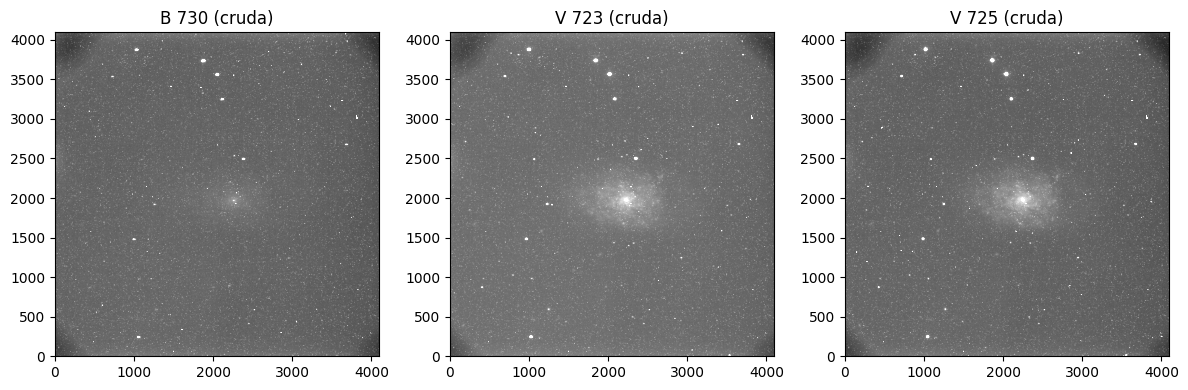

In [5]:
#graficamos algunas exposiciones crudas (cada una con su propia escala)
zscale=ZScaleInterval(contrast=0.25)
fig,ax=plt.subplots(1,3, figsize=(12,4))
for a,img,t in [(ax[0],datab4,'B 730 (cruda)'),(ax[1],datav1,'V 723 (cruda)'),(ax[2],datav3,'V 725 (cruda)')]:
    min_value,max_value=zscale.get_limits(img)
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

### DARKS

In [6]:
# importamos los darks (trabajare con los de 120s)
dark1=fits.open('Dark_120.000secs_00000774.fit')
dark2=fits.open('Dark_120.000secs_00000775.fit')
dark3=fits.open('Dark_120.000secs_00000776.fit')
dark4=fits.open('Dark_120.000secs_00000777.fit')
dark5=fits.open('Dark_120.000secs_00000778.fit')

#extraemos los datos de los darks
datad1=dark1[0].data.astype(np.float32)
datad2=dark2[0].data.astype(np.float32)
datad3=dark3[0].data.astype(np.float32)
datad4=dark4[0].data.astype(np.float32)
datad5=dark5[0].data.astype(np.float32)


In [7]:
#extraemos los datos de los darks
datad1=dark1[0].data.astype(np.float32)
datad2=dark2[0].data.astype(np.float32)
datad3=dark3[0].data.astype(np.float32)
datad4=dark4[0].data.astype(np.float32)
datad5=dark5[0].data.astype(np.float32)

### Maste Dark 

In [8]:
#Como ultilizamos float32 "dividimos" en frajas
def mediana_franjas(lista, paso=256):
    """Mediana pixel a pixel ignorando NaN, procesando 256 filas a la vez."""
    ny,nx=lista[0].shape
    out=np.empty((ny,nx),dtype=np.float32)
    for y in range(0,ny,paso):
        bloque=np.stack([im[y:y+paso] for im in lista])
        out[y:y+paso]=np.nanmedian(bloque,axis=0)
    return out

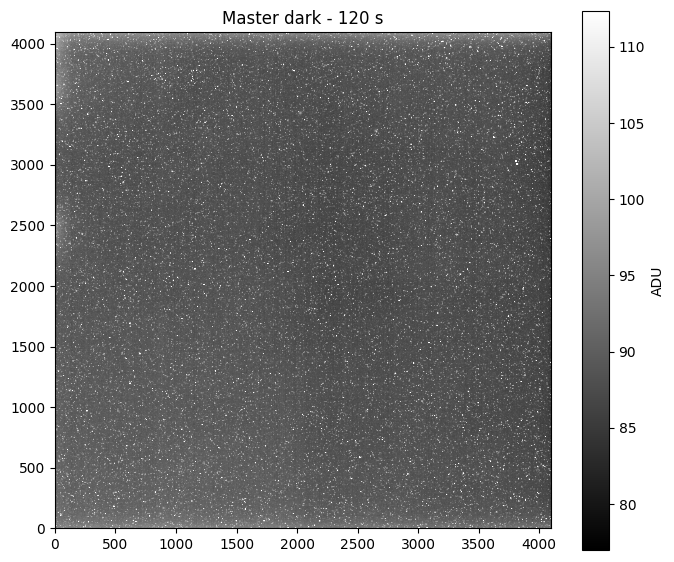

In [9]:
# creamos el master dark usando la mediana de los darks individuales
master_dark = np.nanmedian([datad1, datad2, datad3, datad4, datad5], axis=0)

zscale=ZScaleInterval(contrast=0.25)
min_value,max_value=zscale.get_limits(master_dark[np.isfinite(master_dark)])

plt.figure(figsize=(8,7))
plt.imshow(master_dark,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
plt.colorbar(label='ADU')
plt.title('Master dark - 120 s')
plt.show()

### FLATS

nivel cero: 88.0 ADU
flat B min/max:  -0.00307574 2.2874768
flat V min/max:  -0.0038220987 2.8425555


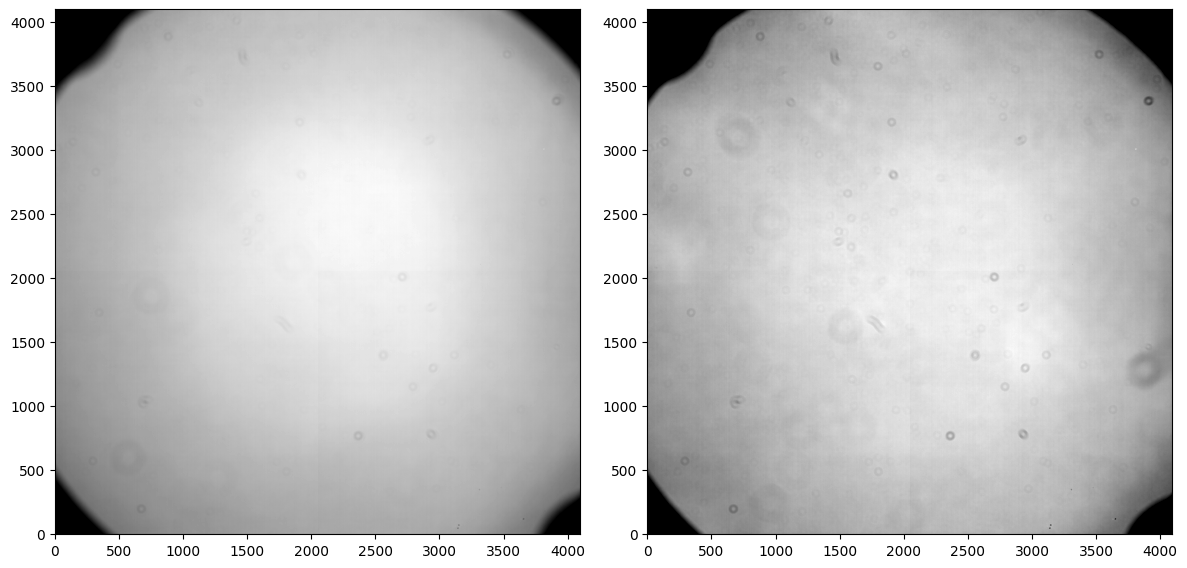

In [10]:
# extraemos los flats del filtro b
flatsB = [fits.open(f'FLAT_B_B11-{n:03}.fit')for n in range(1, 11)] #mas facil q llamar 1 x 1
#extraemos los flats del filtro v
flatsV = [fits.open(f'FLAT_V_B11-{n:03}.fit')for n in range(1, 11)]


#nivel cero del detector (bias): mediana del master dark. Los flats son de 0.5 s, asi que solo se les resta este nivel
nivel_cero = np.nanmedian(master_dark)
print('nivel cero:', nivel_cero, 'ADU')

#Master flat filtro V normalizado (utilizando la mediana)
master_flatv = mediana_franjas([f[0].data.astype(np.float32) - nivel_cero for f in flatsV])
master_flatv_norm = master_flatv / np.nanmedian(master_flatv)



#Master flat filtro b normalizado (utilizando la mediana)
master_flatb = mediana_franjas([f[0].data.astype(np.float32) - nivel_cero for f in flatsB])
master_flatb_norm = master_flatb / np.nanmedian(master_flatb)

print('flat B min/max: ', np.nanmin(master_flatb_norm), np.nanmax(master_flatb_norm))
print('flat V min/max: ', np.nanmin(master_flatv_norm), np.nanmax(master_flatv_norm))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a,f,t in [(ax[0], master_flatb_norm, 'Master Flat B'), (ax[1], master_flatv_norm, 'Master Flat V')]:
    lo, hi = ZScaleInterval(contrast=0.25).get_limits(f)
    im =a.imshow(f, vmin=lo, vmax=hi, cmap='gray', origin='lower')
plt.tight_layout()
plt.show()

In [11]:
bpm = fits.open('BPM.fit')
databpm=bpm[0].data

Valores BPM: (array([0, 1], dtype='>i2'), array([  632422, 16144794]))
Fraccion de pixeles buenos: 0.9623047113418579


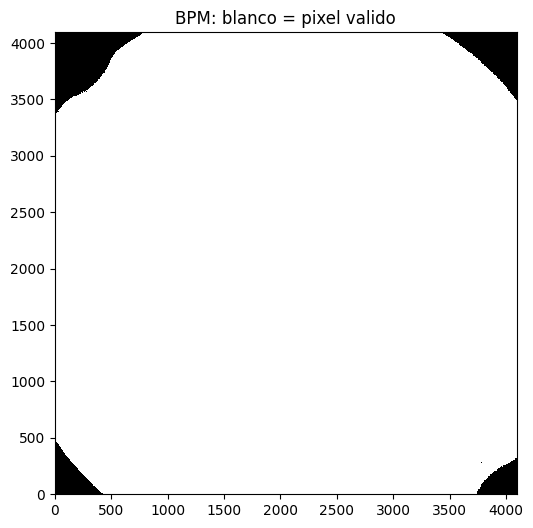

In [12]:
BPM_GOOD_VALUE=1 #1 plixel bueno, 0 pixel malo
FLAT_MIN=0.05   #evita dividir por flats casi nulos

bpm_good=(databpm==BPM_GOOD_VALUE)
print('Valores BPM:', np.unique(databpm,return_counts=True))
print('Fraccion de pixeles buenos:', bpm_good.mean())

plt.figure(figsize=(6,6))
plt.imshow(bpm_good,cmap='gray',origin='lower',interpolation='nearest')
plt.title('BPM: blanco = pixel valido')
plt.show()

#REDUCCIÓN 

In [13]:
def reducir(data, flat_norm):
    valido=(bpm_good & np.isfinite(data) & np.isfinite(master_dark)
            & np.isfinite(flat_norm) & (flat_norm>FLAT_MIN))
    red=np.full(data.shape,np.nan,dtype=np.float32)
    red[valido]=(data[valido]-master_dark[valido])/flat_norm[valido]
    return red

sel_b=[datab1,datab3,datab5]
sel_v=[datav1,datav3]

redb=[reducir(d,master_flatb_norm) for d in sel_b]
redv=[reducir(d,master_flatv_norm) for d in sel_v]

#liberamos las imagenes crudas que ya no se usan
del sel_b,sel_v,datab1,datab2,datab3,datab4,datav1,datav2,datav3,datav4

### IMAGENES FINALES

de cada img ciencia

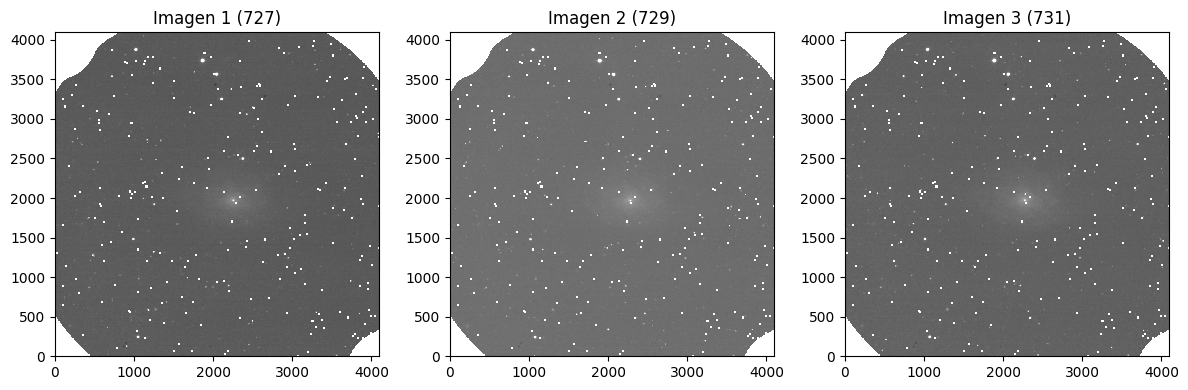

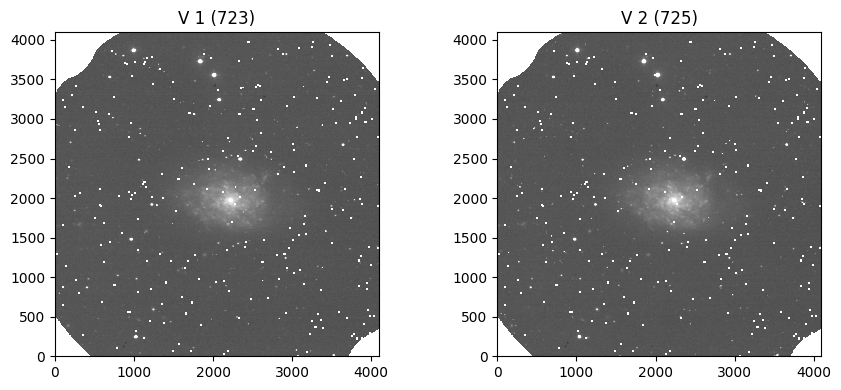

In [14]:
zscale=ZScaleInterval(contrast=0.25)

fig,ax=plt.subplots(1,3, figsize=(12,4))
titulos=['Imagen 1 (727)','Imagen 2 (729)','Imagen 3 (731)']
for a,img,t in zip(ax,redb,titulos):
    min_value,max_value=zscale.get_limits(img[np.isfinite(img)])  #limites propios de cada imagen
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

fig,ax=plt.subplots(1,2, figsize=(9,4))
titulos=['V 1 (723)','V 2 (725)']
for a,img,t in zip(ax,redv,titulos):
    min_value,max_value=zscale.get_limits(img[np.isfinite(img)])
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

alineamos las imagenes

In [15]:
def a_masked(img):
    #astroalign no tolera NaN: se rellenan con la mediana y se marcan en una mascara
    malo=~np.isfinite(img)
    return np.ma.array(np.where(malo,np.nanmedian(img),img),mask=malo)

#las estrellas se detectan aqui y se emparejan por votacion del desplazamiento (las estrellas reales se mueven
#todas igual; los rayos cosmicos y los grumos de la galaxia no). A astroalign se le entregan los pares ya
#emparejados para calcular y aplicar la transformacion (aa.find_transform solo no lograba alinear las imagenes B)
def estrellas(img, n=150):
    from photutils.detection import DAOStarFinder
    im=np.where(np.isfinite(img),img,np.nanmedian(img))
    im=im-ndimage.median_filter(im[::4,::4],25).repeat(4,0).repeat(4,1)   #quita el cielo y la galaxia
    _,med,std=sigma_clipped_stats(im[::4,::4])
    t=DAOStarFinder(fwhm=FWHM_PX,threshold=10*std,exclude_border=True)(im-med)
    t=t[(t['xcentroid']>100)&(t['xcentroid']<im.shape[1]-100)&(t['ycentroid']>100)&(t['ycentroid']<im.shape[0]-100)]
    t.sort('flux')
    t.reverse()
    return np.column_stack([t['xcentroid'],t['ycentroid']])[:n]

def emparejar(p, q, max_shift=300):
    #diferencia de posicion entre todas las parejas posibles: el desplazamiento real es el mas votado
    d=(q[None,:,:]-p[:,None,:]).reshape(-1,2)
    d=d[np.all(np.abs(d)<max_shift,axis=1)]
    h,xe,ye=np.histogram2d(d[:,0],d[:,1],bins=200,range=[[-max_shift,max_shift]]*2)
    i,j=np.unravel_index(h.argmax(),h.shape)
    dx0,dy0=(xe[i]+xe[i+1])/2,(ye[j]+ye[j+1])/2
    #pares: cada estrella de p con la de q que queda a menos de 4 px al aplicar ese desplazamiento
    dist=np.hypot(p[:,None,0]+dx0-q[None,:,0],p[:,None,1]+dy0-q[None,:,1])
    ok=dist.min(axis=1)<4
    return p[ok],q[dist.argmin(axis=1)[ok]]

def alinear(lista, ref, nombres):
    pos_ref=estrellas(ref)
    alineadas=[]
    for i,img in enumerate(lista):
        if img is ref:
            alineadas.append(img.astype(np.float32))
            print(f'{nombres[i]}: referencia')
            continue
        src,dst=emparejar(estrellas(img),pos_ref)
        if len(src)<5:
            print(f'{nombres[i]}: NO se pudo alinear (solo {len(src)} estrellas en comun); se descarta')
            continue
        T=aa.estimate_transform('euclidean',src,dst)     #desplazamiento + rotacion
        al,foot=aa.apply_transform(T,a_masked(img),a_masked(ref),fill_value=np.nan,propagate_mask=True)
        alineadas.append(np.asarray(al,dtype=np.float32))
        print(f'{nombres[i]}: shift (x,y)={T.translation.round(1)} px, '
              f'rot={np.degrees(T.rotation):.3f} deg, estrellas={len(src)}, '
              f'residuo={np.std(T(src)-dst,axis=0).round(2)} px')
    return alineadas

#el orden de estas listas debe coincidir con el orden de redb y redv
nombres_b=['727','729','731']
nombres_v=['723','725']

#B y V se alinean a la misma imagen, V 723, para que los dos filtros queden en la misma grilla de pixeles
referencia=redv[nombres_v.index('723')]
alb=alinear(redb,referencia,nombres_b)
alv=alinear(redv,referencia,nombres_v)
print('Tomas alineadas B:',len(alb),'| V:',len(alv))

727: shift (x,y)=[-24.1   2. ] px, rot=-0.005 deg, estrellas=16, residuo=[0.47 0.12] px
729: shift (x,y)=[-51.8   5.4] px, rot=-0.003 deg, estrellas=17, residuo=[0.48 0.18] px
731: shift (x,y)=[-45.1   1.3] px, rot=-0.002 deg, estrellas=16, residuo=[0.43 0.19] px
723: referencia
725: shift (x,y)=[-20.   -0.7] px, rot=-0.000 deg, estrellas=31, residuo=[0.44 0.23] px
Tomas alineadas B: 3 | V: 2


C:\Users\laneg\AppData\Local\Temp\ipykernel_9576\4029651949.py:8: RuntimeWarning: All-NaN slice encountered
  out[y:y+paso]=np.nanmedian(bloque,axis=0)


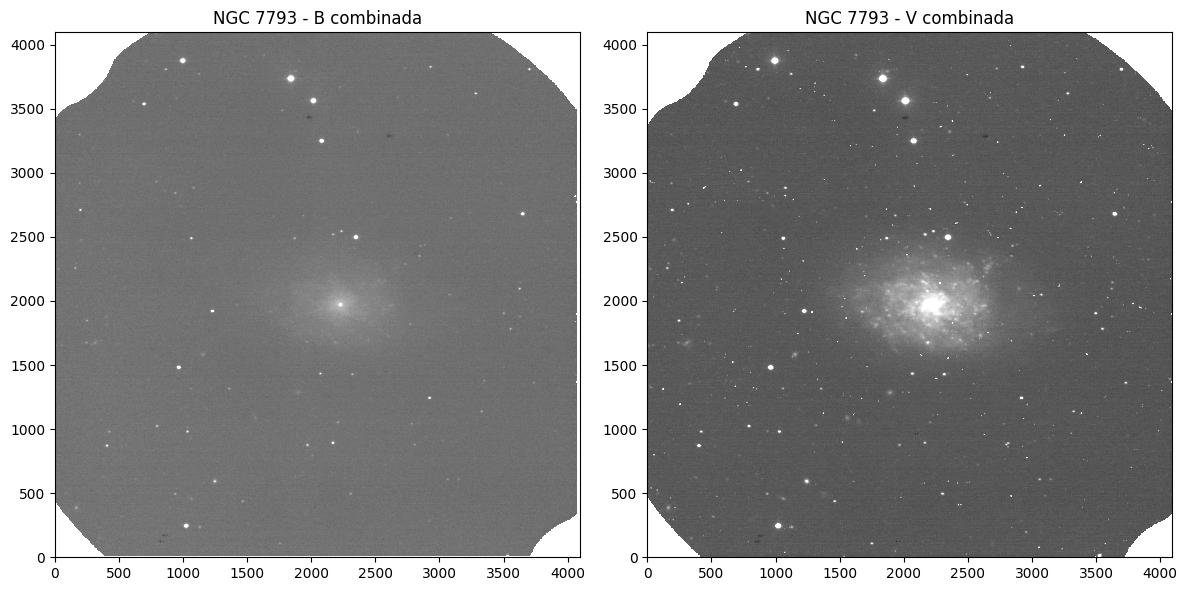

In [16]:
#graficamos ambas imagenes
final_b=mediana_franjas(alb)
final_v=mediana_franjas(alv)

fig,ax=plt.subplots(1,2,figsize=(12,6))
for a,img,t in [(ax[0],final_b,'NGC 7793 - B combinada'),(ax[1],final_v,'NGC 7793 - V combinada')]:
    lo,hi=zscale.get_limits(img[np.isfinite(img)])
    a.imshow(img,vmin=lo,vmax=hi,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

### FITS Y ASTROMETRIA

In [17]:
#Creación fits y astrometría

phdu = fits.PrimaryHDU(header = b1[0].header , data = final_b)
phdu.data = np.float32(phdu.data)

#WCS de partida: solucion de astrometry.net (wcs_15oct.fits), resuelta sobre la grilla de V 723, que es la de las dos imagenes.
#Si no esta, WCS aproximado con el centro del header (OBJCTRA/OBJCTDEC, que el 15/10 quedo ~40' corrido)
phdu.header['PIXSCALE'] = PIXSCALE
if os.path.exists('wcs_15oct.fits'):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        phdu.header.update(WCS(fits.getheader('wcs_15oct.fits')).to_header(relax=True))
else:
    print('No esta wcs_15oct.fits: WCS aproximado con el centro del header')
    phdu.header['CTYPE1'] = 'RA---TAN'
    phdu.header['CTYPE2'] = 'DEC--TAN'
    phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
    phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

    coord = SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}", unit=(u.hourangle, u.deg))#Transformacion de unidades a grados decimales

    phdu.header['CRVAL1'] = coord.ra.value
    phdu.header['CRVAL2'] = coord.dec.value
    phdu.header['CD1_1'] = PIXSCALE/3600   #positivo: la imagen esta espejada (el este queda a la derecha)
    phdu.header['CD1_2'] = 0
    phdu.header['CD2_1'] = 0
    phdu.header['CD2_2'] = PIXSCALE/3600
phdu.header['OBSERVER'] = 'Bustos, Medina, Oyarzo'

phdu.writeto('Img_B.fits', overwrite = True)

In [18]:
#V se guarda con el mismo WCS que B (las dos estan en la grilla de V 723)
hdu_v = fits.PrimaryHDU(header = v1[0].header , data = np.float32(final_v))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    hdu_v.header.update(WCS(phdu.header).to_header(relax=True))
hdu_v.header['PIXSCALE'] = phdu.header['PIXSCALE']
hdu_v.header['OBSERVER'] = phdu.header['OBSERVER']

hdu_v.writeto('Img_V.fits', overwrite = True)

### DETECCION DE OBJETOS

In [19]:
#deteccion de objetos
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)
from astropy.io import fits
from matplotlib import pyplot as plt
import numpy as np
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip
from photutils.utils import calc_total_error

### 1- Para el filtro v

In [20]:
#abrio mi fit filtro v (imagen reduccioda)
#se copian a memoria y el archivo se cierra (en Windows un archivo abierto no se puede volver a grabar)
with fits.open('Img_V.fits', memmap=False) as hdul:
    dataV = hdul[0].data.copy()
    headerV = hdul[0].header.copy()
headerV

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Bustos, Medina, Oyarzo' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{4962eaff-43f2-4b

In [21]:
#restando el fondo
from photutils.background import Background2D, MedianBackground
#FWHM_PX viene del seeing medido en las estandares (primera celda)
print(f'FWHM_PX = {FWHM_PX:.1f} px  (seeing {SEEING:.2f}" / {PIXSCALE} "/px)')

FWHM_PX = 10.0 px  (seeing 3.17" / 0.317 "/px)


In [22]:
#mascara de pixeles invalidos (NaN en los bordes y BPM)
maskV=~np.isfinite(dataV)
#estimamos el cielo y lo restamos (si no, segment_flux incluye el cielo)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    bkgV=Background2D(dataV,64,filter_size=5,bkg_estimator=MedianBackground(),coverage_mask=maskV,fill_value=0.0)
dataV_sub=dataV-bkgV.background
#filtramos con una gaussiana del tamaño del seeing (resalta las estrellas sobre el ruido)
convV=ndimage.gaussian_filter(np.where(maskV,0.0,dataV_sub),FWHM_PX/2.355)

#Obtenemos el "umbral" que utilizaremos para detectar las fuentes EN EL FILTRO V: 4 sigma sobre la imagen filtrada
thresholdV = detect_threshold(convV, nsigma=4, mask=maskV)
#Utilizamos el umbral y la imagen para detectar fuentes
sourV = detect_sources(convV, thresholdV, npixels=50, mask=maskV)
#Mostramos el número de fuentes detectadas
sourV

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
nlabels: 747
labels: [  1   2   3   4   5 ... 743 744 745 746 747]

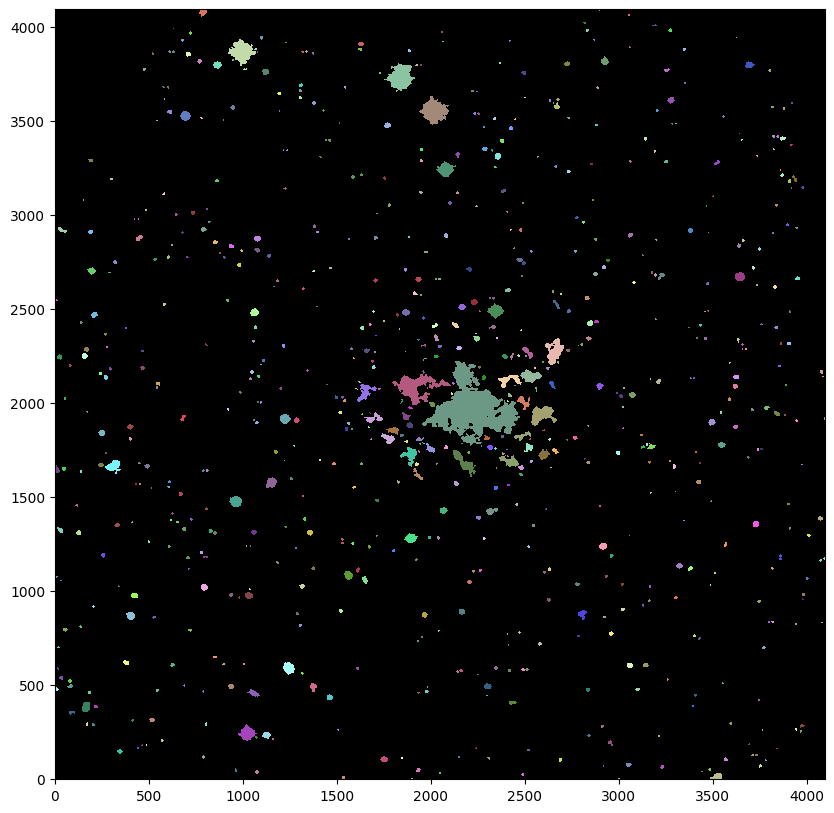

In [23]:
#Generamos un mapa de color para cada fuente del filtro V
cmap_sourV = sourV.make_cmap(seed=123)
#Mostramos las fuentes obtenidas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sourV, origin='lower', cmap=cmap_sourV, interpolation='nearest')
plt.show()

In [24]:
# separamos las fuentes (sobre la imagen filtrada, la misma de la deteccion)
sour_deblend = deblend_sources(convV, sourV, npixels=50, nlevels=32, contrast=0.001)
#esto muestra el numero de fuentes detectadas
sour_deblend

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
nlabels: 870
labels: [  1   2   3   4   5 ... 866 867 868 869 870]

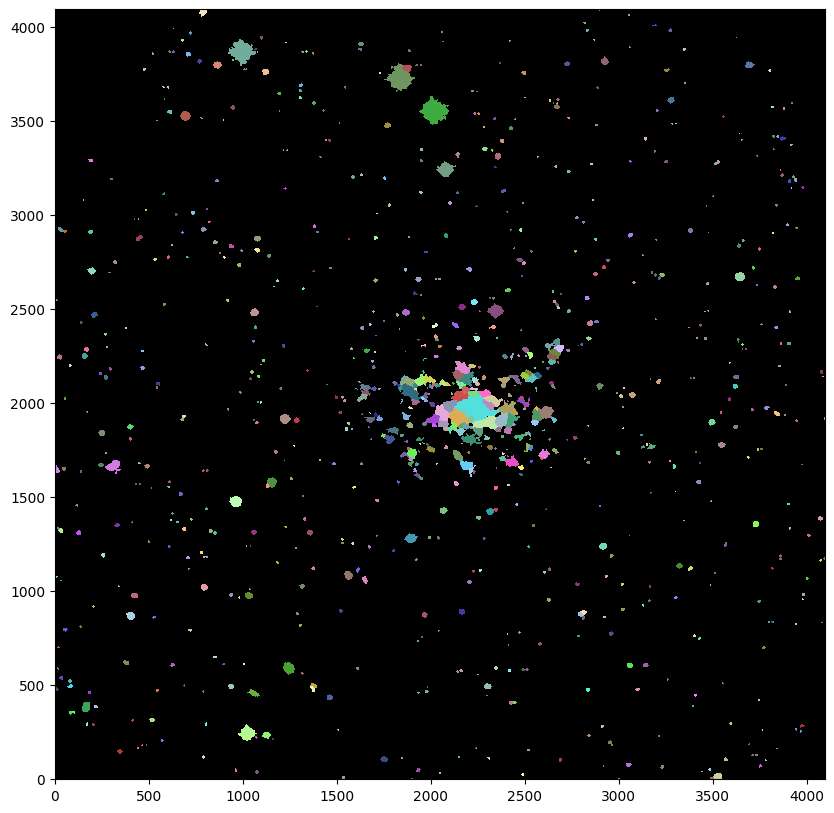

In [25]:
cmap_deblend = sour_deblend.make_cmap(seed=123)
#muesta las fuentes detectadas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sour_deblend, origin='lower', cmap= cmap_deblend, interpolation='nearest')
plt.show()

In [26]:
#OBTENEMOS EL CATALOGO DE FITS REDUCIDO PARA EL FILTRO V
#OBTENEMOS EL CATALOGO DE FITS REDUCIDO PARA EL FILTRO B
#error de cada pixel: ruido del cielo (rms del fondo) + ruido de Poisson de la fuente. El apilado combina
#len(alb) exposiciones, asi que la ganancia efectiva es GAIN*len(alb) (e-/ADU)
errV = calc_total_error(dataV_sub, bkgV.background_rms, effective_gain=headerV['GAIN']*len(alb))
catV = SourceCatalog(dataV_sub, sour_deblendV, convolved_data=convV, error=errV, mask=maskV)
#pasamos el catalogo a una tabla (solo con los datos que nos interesan)
tb1V = catV.to_table()
tablaV = tb1V['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux', 'segment_fluxerr']
#label: numero id de la fuente
#xcentroid, ycentroid: coordenadas en pixeles
#area: tamaño en pixeles
#segment_flux, segment_fluxerr: flujo total del segmento y su error, en ADU (falta dividir por el tiempo de exposicion)

tablaV

NameError: name 'sour_deblendV' is not defined

In [ ]:
#calculamos el flujo real (ADU/s) y su error
tablav['segment_flux'] = tablav['segment_flux']/headerV['EXPTIME']
tablav['segment_fluxerr'] = tablav['segment_fluxerr']/headerV['EXPTIME']

#CALCULAMOS MAG APARENTES CON EL ZEROPOINT
# m = ZP - k*X - 2.5*log10(flujo),  con k la extincion y X la masa de aire
# ZP_V sale de las estrellas estandar (pendiente de revisar); K_V es un valor tipico, no medido
ZP_V, ZP_V_ERR = 21.715, 0.012
K_V = 0.15
zeropointV = ZP_V - K_V*headerV['AIRMASS']
flujo = np.asarray(tablav['segment_flux'], dtype=float)
error = np.asarray(tablav['segment_fluxerr'], dtype=float)
# error: 1.0857*error/flujo (= 2.5/ln(10)), sumado en cuadratura con el error del ZP
with np.errstate(invalid='ignore', divide='ignore'):
    tablav['magnitude'] = np.where(flujo > 0, zeropointV - 2.5*np.log10(flujo), np.nan)
    tablav['magnitude_err'] = np.where(flujo > 0, np.hypot(1.0857*error/flujo, ZP_V_ERR), np.nan)
tablav

In [ ]:
#Mostramos las magnitudes
np.sort(tablav['magnitude'])

### 2- Para el filtro B

In [ ]:
#ahora para filtro b, abro mi fit filtro b (imagen reduccioda)
with fits.open('Img_B.fits', memmap=False) as hdul:
    dataB = hdul[0].data.copy()
    headerB = hdul[0].header.copy()
headerB

In [ ]:
#mascara de pixeles invalidos (NaN en los bordes y BPM)
maskB=~np.isfinite(dataB)
#estimamos el cielo y lo restamos (si no, segment_flux incluye el cielo)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    bkgB=Background2D(dataB,64,filter_size=5,bkg_estimator=MedianBackground(),coverage_mask=maskB,fill_value=0.0)
dataB_sub=dataB-bkgB.background
#filtramos con una gaussiana del tamaño del seeing (resalta las estrellas sobre el ruido)
convB=ndimage.gaussian_filter(np.where(maskB,0.0,dataB_sub),FWHM_PX/2.355)

#Obtenemos el "umbral" que utilizaremos para detectar las fuentes EN EL FILTRO B: 4 sigma sobre la imagen filtrada
thresholdB = detect_threshold(convB, nsigma=4, mask=maskB)
#Utilizamos el umbral y la imagen para detectar fuentes
sourB = detect_sources(convB, thresholdB, npixels=50, mask=maskB)
#Mostramos el número de fuentes detectadas
sourB

In [ ]:
#Generamos un mapa de color para cada fuente del filtro B
cmap_sourB = sourB.make_cmap(seed=123)
#Mostramos las fuentes obtenidas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sourB, origin='lower', cmap=cmap_sourB, interpolation='nearest')
plt.show()

In [ ]:
# separamos las fuentes (sobre la imagen filtrada, la misma de la deteccion)
sour_deblendB = deblend_sources(convB, sourB, npixels=50, nlevels=32, contrast=0.001)
#esto muestra el numero de fuentes detectadas
sour_deblendB

In [ ]:
cmap_deblendB = sour_deblendB.make_cmap(seed=123)
#muesta las fuentes detectadas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sour_deblendB, origin='lower', cmap= cmap_deblendB, interpolation='nearest')
plt.show()

In [ ]:
#OBTENEMOS EL CATALOGO DE FITS REDUCIDO PARA EL FILTRO B
#error de cada pixel: ruido del cielo (rms del fondo) + ruido de Poisson de la fuente. El apilado combina
#len(alb) exposiciones, asi que la ganancia efectiva es GAIN*len(alb) (e-/ADU)
errB = calc_total_error(dataB_sub, bkgB.background_rms, effective_gain=headerB['GAIN']*len(alb))
catB = SourceCatalog(dataB_sub, sour_deblendB, convolved_data=convB, error=errB, mask=maskB)
#pasamos el catalogo a una tabla (solo con los datos que nos interesan)
tb1B = catB.to_table()
tablaB = tb1B['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux', 'segment_fluxerr']
#label: numero id de la fuente
#xcentroid, ycentroid: coordenadas en pixeles
#area: tamaño en pixeles
#segment_flux, segment_fluxerr: flujo total del segmento y su error, en ADU (falta dividir por el tiempo de exposicion)

tablaB

In [ ]:
#calculamos el flujo real (ADU/s) y su error
tablaB['segment_flux'] = tablaB['segment_flux']/headerB['EXPTIME']
tablaB['segment_fluxerr'] = tablaB['segment_fluxerr']/headerB['EXPTIME']

#CALCULAMOS MAG APARENTES CON EL ZEROPOINT
# m = ZP - k*X - 2.5*log10(flujo),  con k la extincion y X la masa de aire
# ZP_B sale de las estrellas estandar (pendiente de revisar); K_B es un valor tipico, no medido
# el ZP de B vale para B-V = 0: falta el termino de color, asi que 'magnitude' es B0 y no B
ZP_B, ZP_B_ERR = 19.362, 0.014
K_B = 0.25
zeropointB = ZP_B - K_B*headerB['AIRMASS']
flujo = np.asarray(tablaB['segment_flux'], dtype=float)
error = np.asarray(tablaB['segment_fluxerr'], dtype=float)
# error: 1.0857*error/flujo (= 2.5/ln(10)), sumado en cuadratura con el error del ZP
with np.errstate(invalid='ignore', divide='ignore'):
    tablaB['magnitude'] = np.where(flujo > 0, zeropointB - 2.5*np.log10(flujo), np.nan)
    tablaB['magnitude_err'] = np.where(flujo > 0, np.hypot(1.0857*error/flujo, ZP_B_ERR), np.nan)
tablaB

In [ ]:
#Mostramos las magnitudes
np.sort(tablaB['magnitude'])